# 01 – Làm sạch dữ liệu Online Retail II



Quy trình trong notebook: **xem dữ liệu → nhận xét → đề xuất phương án → xử lý → lưu dữ liệu sạch**.

**Các bước xử lý:** điền Description thiếu → bỏ dòng trùng → lọc giao dịch hợp lệ (bỏ hóa đơn hủy, `Quantity > 0`, `Price > 0`, bỏ mã hàng đặc biệt) → bỏ ngoại lai cực đoan → điền Customer ID thiếu = "Guest". Kèm chuẩn hóa văn bản và đổi `EIRE → Ireland`.


> Dữ liệu gốc trong `data/raw/` không bị sửa.

## 1. Import thư viện và đọc dữ liệu

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as pp
print("Thư mục gốc:", ROOT)

File Excel có **2 sheet** (2009-2010 và 2010-2011). Đọc cả hai rồi gộp lại, nếu chỉ dùng `read_excel` mặc định sẽ mất một sheet.

In [ ]:


sheets = pd.read_excel(PATH, sheet_name=None)   
for name, part in sheets.items():
    print(name, part.shape)

df = pd.concat(sheets.values(), ignore_index=True)
print("Sau khi gộp:", df.shape)
df.head()

Year 2009-2010 (525461, 8)
Year 2010-2011 (541910, 8)


Sau khi gộp: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom


## 2. Xem tổng quan dữ liệu

### 2.1. Kích thước, kiểu dữ liệu

In [ ]:
print("shape:", df.shape)
print("size :", df.size)
print("Bộ nhớ: %.1f MB" % (df.memory_usage(deep=True).sum() / 1024**2))
df.info()

shape: (1067371, 8)
size : 8538968


Bộ nhớ: 249.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


### 2.2. Thống kê mô tả

In [ ]:

display(df[["Quantity", "Price"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,1067371.000,9.939,172.706,-80995.000,-3.000,1.000,3.000,10.000,100.000,80995.000
Price,1067371.000,4.649,123.553,-53594.360,0.210,1.250,2.100,4.150,18.000,38970.000


In [ ]:

display(df.select_dtypes(exclude=["number", "datetime"]).describe().T)
display(df[["InvoiceDate"]].describe().T)

,count,unique,top,freq
Invoice,1067371,53628,537434,1350
StockCode,1067371,5305,85123A,5829
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918
Country,1067371,43,United Kingdom,981330


,count,mean,min,25%,50%,75%,max
InvoiceDate,1067371,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00


### 2.3. Độ lệch (skew) và tứ phân vị

In [ ]:
rows = []
for col in ["Quantity", "Price"]:
    s = df[col]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    rows.append({"Cột": col, "Skew": s.skew(), "Kurtosis": s.kurt(), "Q1": q1, "Median": s.median(),
                 "Q3": q3, "IQR": iqr, "Hàng rào dưới": q1 - 1.5 * iqr, "Hàng rào trên": q3 + 1.5 * iqr,
                 "Min": s.min(), "Max": s.max()})
display(pd.DataFrame(rows).set_index("Cột").T)

Cột,Quantity,Price
Skew,3.996,-69.165
Kurtosis,155059.693,73751.829
Q1,1.000,1.250
Median,3.000,2.100
Q3,10.000,4.150
IQR,9.000,2.900
Hàng rào dưới,-12.500,-3.100
Hàng rào trên,23.500,8.500
Min,-80995.000,-53594.360
Max,80995.000,38970.000


### 2.4. Số lượng giá trị duy nhất

In [ ]:
print("Số hóa đơn      :", df["Invoice"].nunique())
print("Số khách hàng   :", df["Customer ID"].nunique())
print("Số mã sản phẩm  :", df["StockCode"].nunique())
print("Số quốc gia     :", df["Country"].nunique())
print("Từ", df["InvoiceDate"].min(), "đến", df["InvoiceDate"].max())

Số hóa đơn      : 53628
Số khách hàng   : 5942
Số mã sản phẩm  : 5305
Số quốc gia     : 43
Từ 2009-12-01 07:45:00 đến 2011-12-09 12:50:00


📝 **Nhận xét phần 2:**
- Dữ liệu có **1.067.371 dòng × 8 cột**, mỗi dòng là *một mặt hàng trên một hóa đơn* (không phải một khách hàng). Kiểu dữ liệu nhìn chung hợp lý; `InvoiceDate` đã là datetime nên không cần convert. `Customer ID` đang là `float64` vì có NaN, và sau khi xử lý thiếu cần đổi sang chuỗi/số nguyên.
- **Mean ≫ median** ở cả hai cột (Quantity trung bình khoảng 9–10 còn trung vị là 3; Price trung bình khoảng 4,6 còn trung vị khoảng 2). Kurtosis rất lớn và `Max` cách Q3 hàng trăm đến hàng nghìn lần → phân phối **lệch phải mạnh, đuôi dài**.
- Giá trị **min/max rất lạ**: Quantity từ -80.995 đến +80.995, Price từ -53.594 đến +38.970. Skew của `Price` ra **âm** (khoảng -69) không phải do giá hàng thật lệch trái mà do 5 dòng giá âm cực trị (`Adjust bad debt`). Vì vậy chưa nên đọc độ lệch khi chưa loại các lỗi nghiệp vụ.
- Có khoảng 5.900 khách hàng có ID, 43 quốc gia, dữ liệu từ 01/12/2009 đến 09/12/2011.

## 3. Kiểm tra chất lượng dữ liệu

### 3.1. Dữ liệu thiếu

In [ ]:
missing = pd.DataFrame({
    "Số thiếu": df.isnull().sum(),
    "Tỷ lệ (%)": (df.isnull().sum() / len(df) * 100).round(2),
})
display(missing)

is_c = df["Invoice"].astype(str).str.startswith("C")
print("Thiếu Customer ID trong hóa đơn hủy   :", f"{df.loc[is_c, 'Customer ID'].isna().mean():.1%}")
print("Thiếu Customer ID trong hóa đơn thường:", f"{df.loc[~is_c, 'Customer ID'].isna().mean():.1%}")
miss_desc = df[df["Description"].isna()]
print("Dòng thiếu Description:", len(miss_desc),
      "| trong đó Price == 0:", int((miss_desc["Price"] == 0).sum()),
      "| tổng Quantity×Price của các dòng này:", float((miss_desc["Quantity"] * miss_desc["Price"]).sum()))

,Số thiếu,Tỷ lệ (%)
Invoice,0,0.000
StockCode,0,0.000
Description,4382,0.410
Quantity,0,0.000
InvoiceDate,0,0.000
Price,0,0.000
Customer ID,243007,22.770
Country,0,0.000


Thiếu Customer ID trong hóa đơn hủy   : 3.8%
Thiếu Customer ID trong hóa đơn thường: 23.1%
Dòng thiếu Description: 4382 | trong đó Price == 0: 4382 | tổng Quantity×Price của các dòng này: 0.0


### 3.2. Dòng trùng lặp

In [ ]:
dup_total = df.duplicated().sum()
dup_within = sum(part.duplicated().sum() for part in sheets.values())
print("Số dòng trùng hoàn toàn:", dup_total, f"({dup_total/len(df):.2%})")
print(" - Trùng ngay trong cùng 1 sheet:", dup_within)
print(" - Trùng giữa 2 sheet (do chồng lấn thời gian):", dup_total - dup_within)
s1, s2 = list(sheets.values())
print("Sheet 1 kết thúc:", s1["InvoiceDate"].max(), "| Sheet 2 bắt đầu:", s2["InvoiceDate"].min())

Số dòng trùng hoàn toàn: 34335 (3.22%)
 - Trùng ngay trong cùng 1 sheet: 12133
 - Trùng giữa 2 sheet (do chồng lấn thời gian): 22202
Sheet 1 kết thúc: 2010-12-09 20:01:00 | Sheet 2 bắt đầu: 2010-12-01 08:26:00


### 3.3. Hóa đơn hủy, Quantity và Price không hợp lệ

In [ ]:
df["Invoice"] = df["Invoice"].astype(str)
cancelled = df["Invoice"].str.startswith("C")

print("Dòng thuộc hóa đơn hủy (bắt đầu bằng C):", cancelled.sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("  trong đó KHÔNG phải hóa đơn hủy:", ((df["Quantity"] <= 0) & ~cancelled).sum())
print("Hóa đơn hủy mà Quantity > 0:", (cancelled & (df["Quantity"] > 0)).sum())
print("Price == 0   :", (df["Price"] == 0).sum())
print("Price < 0    :", (df["Price"] < 0).sum())
display(df[(df["Quantity"] <= 0) & ~cancelled]["Description"].value_counts(dropna=False).head(6).to_frame("số dòng"))

Dòng thuộc hóa đơn hủy (bắt đầu bằng C): 19494
Quantity <= 0: 22950
  trong đó KHÔNG phải hóa đơn hủy: 3457
Hóa đơn hủy mà Quantity > 0: 1
Price == 0   : 6202
Price < 0    : 5


,số dòng
Description,
NaN,2689
check,123
damages,84
?,83
damaged,78
missing,27


### 3.4. Mã sản phẩm không phải hàng hóa (bưu phí, phí ngân hàng...)

In [ ]:
df["StockCode"] = df["StockCode"].astype(str)
is_product = df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")

print("Số dòng có StockCode lạ:", (~is_product).sum())
odd = df.loc[~is_product].assign(StockCode=lambda d: d["StockCode"].str.upper())
display(odd.groupby("StockCode").agg(số_dòng=("Invoice", "size"), giá_TB=("Price", "mean"),
        mô_tả=("Description", lambda s: s.dropna().iloc[0] if s.notna().any() else None))
        .sort_values("số_dòng", ascending=False).head(15))

Số dòng có StockCode lạ: 6094


,số_dòng,giá_TB,mô_tả
StockCode,,,
POST,2122,32.623,POSTAGE
DOT,1446,223.145,DOTCOM POSTAGE
M,1426,526.933,Manual
C2,282,49.461,CARRIAGE
D,177,72.867,Discount
S,104,60.957,SAMPLES
BANK CHARGES,102,359.034,Bank Charges
ADJUST,67,163.591,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,7646.089,AMAZON FEE


📝 **Nhận xét phần 3:**
- **Customer ID thiếu nhiều nhất: 243.007 dòng (~22,8%)**; Description thiếu 4.382 dòng (~0,4%). Điểm đáng chú ý: **cả 4.382 dòng thiếu Description đều có `Price = 0`**, nên giá trị giao dịch của chúng bằng 0 (xem kết quả cell trên).
- **34.335 dòng trùng hoàn toàn**; phần lớn là do **hai sheet chồng lấn** nhau những ngày đầu tháng 12/2010 (cùng một giao dịch xuất hiện ở cả hai sheet), phần còn lại là trùng ngay trong một sheet (cùng hóa đơn, mã hàng, số lượng, giá, giờ-phút).
- **Hóa đơn hủy (tiền tố C) có 19.494 dòng, gần như đều có Quantity âm (chỉ 1 dòng ngoại lệ).** Ngoài ra còn khoảng 3,5 nghìn dòng Quantity ≤ 0 **không** có tiền tố C, mô tả là `damaged`, `check`, `missing`… → đó là bút toán kho chứ không phải giao dịch mua bán. Vậy hai nhóm *không trùng hoàn toàn nhau*, phải lọc bằng `Quantity > 0` chứ không chỉ bỏ hóa đơn có chữ C.
- `Price = 0` có 6.202 dòng (tặng/điều chỉnh/lỗi), `Price < 0` có 5 dòng (`Adjust bad debt`).
- Các **StockCode lạ** như `POST`, `D`, `M`, `BANK CHARGES`, `AMAZONFEE`, `ADJUST`… là phí/bưu phí/chiết khấu, giá trung bình rất cao (hàng chục đến hàng nghìn bảng), nên nếu giữ sẽ làm **doanh thu và tổng tiền của khách bị sai lệch**.

## 4. Vẽ hình để xem dữ liệu

### 4.1. Histogram – xem dữ liệu có lệch không

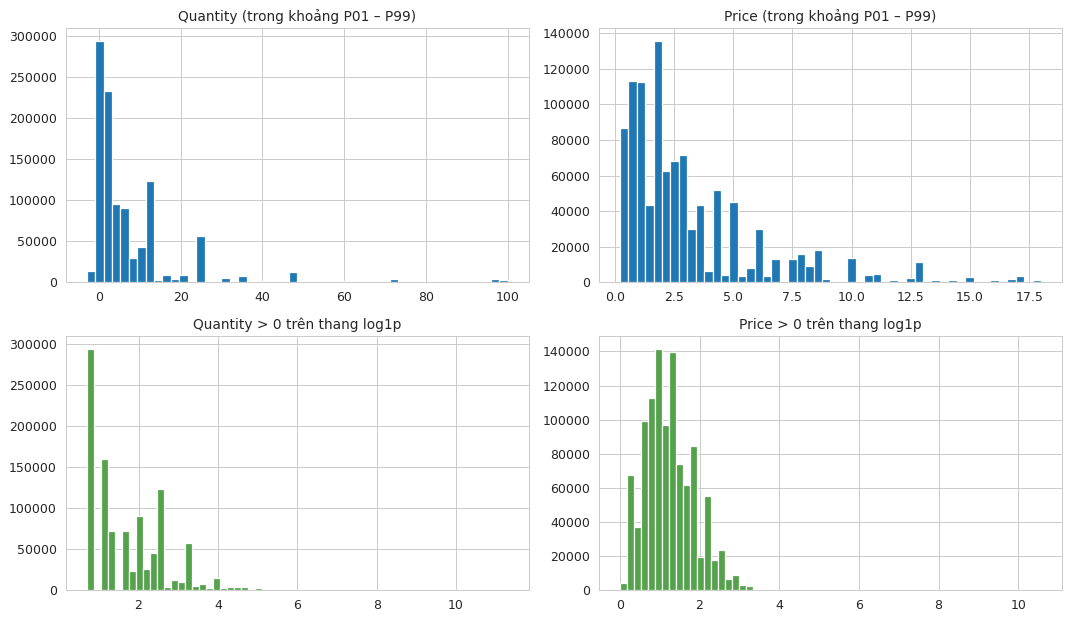

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, col in enumerate(["Quantity", "Price"]):
    low, high = df[col].quantile([0.01, 0.99])
    df.loc[df[col].between(low, high), col].hist(bins=50, ax=axes[0, j])
    axes[0, j].set_title(f"{col} (trong khoảng P01 – P99)")
    pos = df.loc[df[col] > 0, col]
    axes[1, j].hist(np.log1p(pos), bins=60, color="#54A24B")
    axes[1, j].set_title(f"{col} > 0 trên thang log1p")
plt.tight_layout(); plt.show()

### 4.2. Boxplot – xem có ngoại lai không

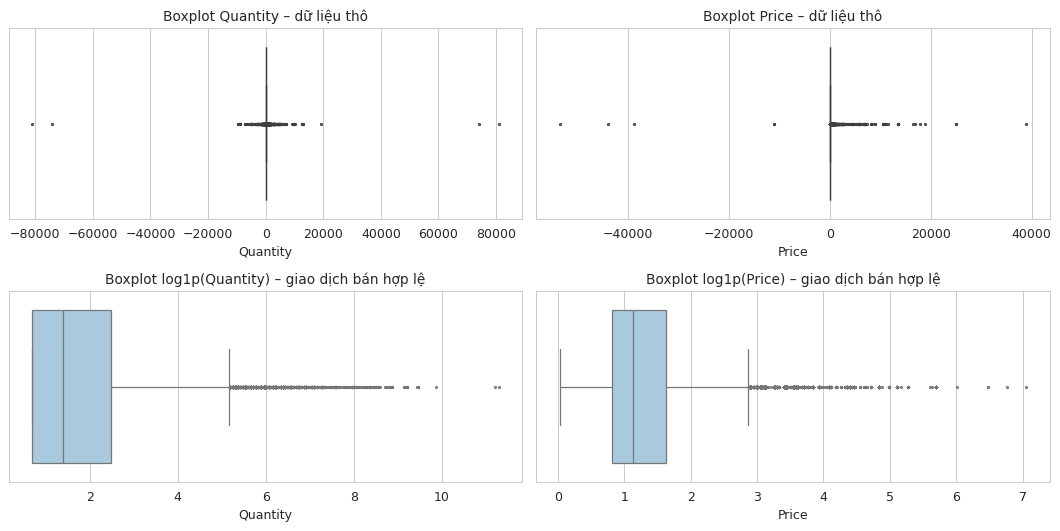

In [ ]:
valid = df[~cancelled & (df["Quantity"] > 0) & (df["Price"] > 0) & is_product].copy()   # giao dịch bán hợp lệ, để xem ngoại lai thật

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, col in enumerate(["Quantity", "Price"]):
    sns.boxplot(x=df[col], ax=axes[0, j], fliersize=1.5); axes[0, j].set_title(f"Boxplot {col} – dữ liệu thô")
    sns.boxplot(x=np.log1p(valid[col]), ax=axes[1, j], fliersize=1.5, color="#A0CBE8")
    axes[1, j].set_title(f"Boxplot log1p({col}) – giao dịch bán hợp lệ")
plt.tight_layout(); plt.show()

### 4.3. Countplot – quốc gia và khách có/không có ID

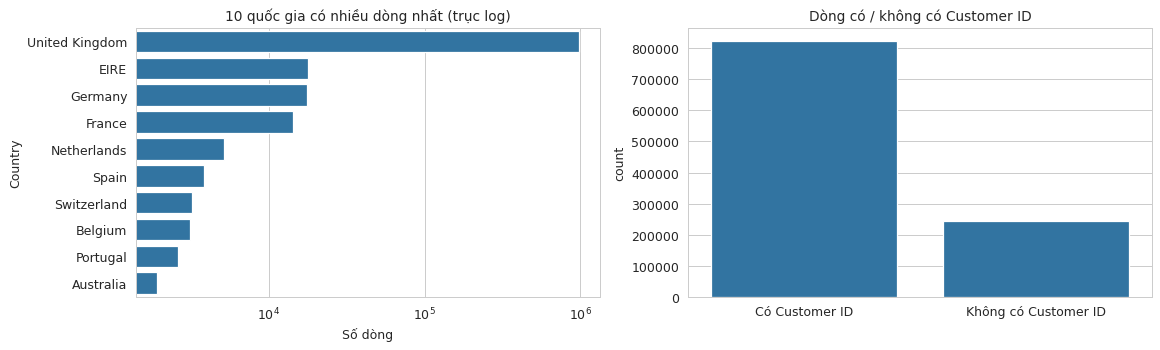

Tỷ trọng United Kingdom: 91.9% | 'EIRE': 17866 | 'Ireland': 0


In [ ]:
top_country = df["Country"].value_counts().head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=top_country.values, y=top_country.index, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("10 quốc gia có nhiều dòng nhất (trục log)"); axes[0].set_xlabel("Số dòng")
guest = df["Customer ID"].isna().map({True: "Không có Customer ID", False: "Có Customer ID"})
sns.countplot(x=guest, ax=axes[1]); axes[1].set_title("Dòng có / không có Customer ID"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("Tỷ trọng United Kingdom:", f"{(df['Country'] == 'United Kingdom').mean():.1%}", "| 'EIRE':", int((df['Country'] == 'EIRE').sum()), "| 'Ireland':", int((df['Country'] == 'Ireland').sum()))

### 4.4. Chọn ngưỡng ngoại lai: IQR × 1,5 hay × 3?

Trước khi bỏ ngoại lai, mình **đo thử tác động** của hai ngưỡng trên giao dịch bán hợp lệ (đã bỏ lỗi nghiệp vụ), dùng thang `log1p` vì dữ liệu lệch mạnh. Cột "Chi tiêu 50 khách lớn nhất còn lại" cho biết nhóm khách giá trị cao có bị cắt mất hay không.

,Dòng bị loại,% dòng,% doanh thu bị mất,Khách mất hoàn toàn,Chi tiêu 50 khách lớn nhất còn lại (%)
Hệ số IQR,,,,,
1.500,16732,1.614,16.568,44,60.255
3.000,478,0.046,2.400,3,93.656


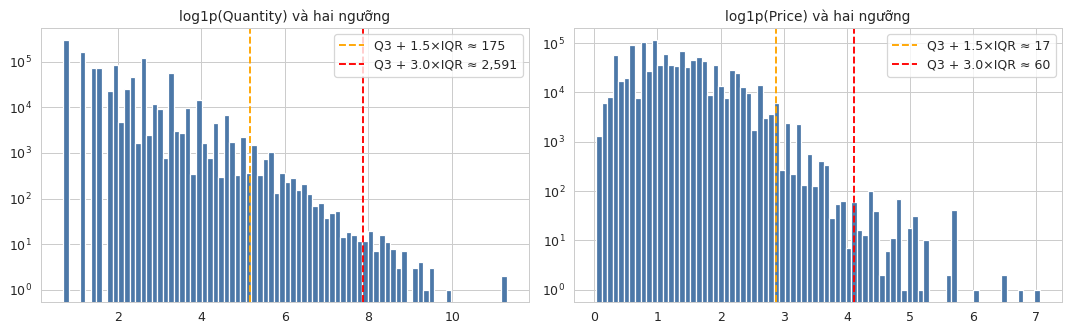

In [ ]:
reg = valid.assign(Revenue=valid["Quantity"] * valid["Price"])
cust_spend = reg[reg["Customer ID"].notna()].groupby("Customer ID")["Revenue"].sum()
top50 = cust_spend.nlargest(50).index

def impact(k):
    mask = pp.outlier_mask(reg, k=k)
    kept = reg[~mask]
    kept_spend = kept[kept["Customer ID"].notna()].groupby("Customer ID")["Revenue"].sum()
    return {"Hệ số IQR": k, "Dòng bị loại": int(mask.sum()), "% dòng": 100 * mask.mean(),
            "% doanh thu bị mất": 100 * reg.loc[mask, "Revenue"].sum() / reg["Revenue"].sum(),
            "Khách mất hoàn toàn": len(set(cust_spend.index) - set(kept_spend.index)),
            "Chi tiêu 50 khách lớn nhất còn lại (%)": 100 * kept_spend.reindex(top50).fillna(0).sum() / cust_spend[top50].sum()}

display(pd.DataFrame([impact(1.5), impact(3.0)]).set_index("Hệ số IQR"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["Quantity", "Price"]):
    x = np.log1p(reg[col]); q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    ax.hist(x, bins=80, color="#4C78A8")
    for k, c in [(1.5, "orange"), (3.0, "red")]:
        ax.axvline(q3 + k * iqr, color=c, ls="--", label=f"Q3 + {k}×IQR ≈ {np.expm1(q3 + k * iqr):,.0f}")
    ax.set_yscale("log"); ax.set_title(f"log1p({col}) và hai ngưỡng"); ax.legend()
plt.tight_layout(); plt.show()

📝 **Nhận xét phần 4:**
- **Histogram:** cả `Quantity` và `Price` lệch **phải** rất mạnh (thân dồn về giá trị nhỏ, đuôi kéo dài); sau `log1p` histogram gần dạng chuông → dữ liệu gần log-normal, nên xét ngoại lai nên làm trên thang log.
- **Boxplot:** trên dữ liệu thô boxplot bị ép dẹt vì vài điểm quá lớn (±80.995 cái, giá tới 38.970); sau khi bỏ lỗi nghiệp vụ và lấy log thì vẫn còn nhiều điểm ngoài râu. Những điểm đó **không toàn là lỗi**: nhiều đơn là khách **mua sỉ thật** (12, 24, 144 cái/mã), chỉ một số ít cực đoan như 80.995 cái là đơn nhập nhầm rồi bị hủy.
- **Quốc gia:** United Kingdom chiếm ~92% số dòng; còn lại nhỏ lẻ. Giá trị `EIRE` (17.866 dòng) thực chất là Ireland và chưa có nhãn `Ireland` nào, nên đổi tên cho nhất quán.
- **Ngưỡng ngoại lai:** cắt theo **IQR × 1,5** chỉ mất ~1,6% số dòng nhưng làm mất **~17% doanh thu**, 44 khách biến mất hoàn toàn và 50 khách chi tiêu lớn nhất mất khoảng 40% chi tiêu — đây chính là nhóm khách giá trị cao mà đề tài muốn tìm. Cắt theo **IQR × 3** chỉ mất ~0,05% số dòng (~2,4% doanh thu), còn giữ khoảng 94% chi tiêu của 50 khách lớn nhất → chọn **IQR × 3 trên log1p**. (Số dòng ở mục này tính trước khi bỏ trùng nên hơi nhiều hơn số thực tế ở Bước 4.)

## 5. Đề xuất phương án xử lý

Số dòng của từng vấn đề được tính ở cell code ngay bên dưới bảng; bảng nêu phương án đề xuất và lý do.

| Vấn đề | Phương án đề xuất | Lý do |
|---|---|---|
| Thiếu Description | Điền `"Unknown Product"` | Không mất dòng và không mất doanh thu. **Lưu ý:** cả các dòng này đều có `Price = 0` nên vẫn sẽ bị loại ở bước lọc `Price > 0` |
| Dòng trùng | Loại bỏ (`drop_duplicates`) | Bản sao do hai sheet chồng lấn và do ghi lặp, giữ lại sẽ nhân đôi Frequency và Monetary |
| Hóa đơn hủy (C) | Loại bỏ khỏi dữ liệu | Để tính doanh thu từ đơn thành công, không để tiền âm triệt tiêu doanh thu |
| `Quantity <= 0` | Loại bỏ | Gồm hóa đơn hủy và bút toán kho (`damaged`, `check`), không phải giao dịch mua |
| `Price <= 0` | Loại bỏ | Hàng tặng/điều chỉnh, không tạo doanh thu |
| StockCode không phải hàng hóa | Loại bỏ toàn bộ danh sách mã dịch vụ | Phí/chiết khấu làm lệch doanh thu từng khách. Danh sách gồm `POST`, `D`, `M`, `BANK CHARGES`, `DOT`, `C2`, `ADJUST`, `AMAZONFEE`, `CRUK`, `TEST001`... |
| Ngoại lai Quantity, Price | Loại bỏ **ngoại lai cực đoan**: ngoài Q1 − 3×IQR, Q3 + 3×IQR trên `log1p` | Dữ liệu log-normal; IQR × 1,5 mất ~17% doanh thu và cắt khách lớn (mục 4.4); chọn ngưỡng nhẹ để không xóa khách mua sỉ thật |
| Thiếu Customer ID | Điền `"Guest"`, thêm cột cờ `IsGuest` | Giữ doanh thu của khách vãng lai và phân biệt khách có ID/khách lẻ. **Khi tính RFM phải bỏ `Guest`**, vì nó gộp nhiều người mua khác nhau thành một "khách" khổng lồ |
| `EIRE`, khoảng trắng, chữ hoa/thường | Đổi `EIRE → Ireland`, `strip`, viết hoa Description | Cùng một giá trị phải có cùng một cách viết (làm trước bước bỏ trùng để bắt được trùng do khác khoảng trắng) |
| Kiểu dữ liệu `Customer ID` | Đổi sang chuỗi sau khi điền thiếu | Cột có cả số lẫn `"Guest"` nên không thể là số nguyên |

In [ ]:
sc = df["StockCode"].str.strip().str.upper()
summary = pd.DataFrame({"Số dòng": {
    "Thiếu Customer ID": int(df["Customer ID"].isna().sum()),
    "Thiếu Description": int(df["Description"].isna().sum()),
    "Dòng trùng": int(df.duplicated().sum()),
    "Hóa đơn hủy (Invoice bắt đầu bằng C)": int(cancelled.sum()),
    "Quantity <= 0": int((df["Quantity"] <= 0).sum()),
    "Price <= 0": int((df["Price"] <= 0).sum()),
    "StockCode đặc biệt (trong danh sách loại)": int(sc.isin(pp.SPECIAL_CODES).sum()),
    "Country = 'EIRE'": int((df["Country"] == "EIRE").sum()),
    "Ngoại lai cực đoan (IQR×3 trên log1p, sau khi lọc hợp lệ)": int(pp.outlier_mask(reg, k=3.0).sum()),
}})
summary["% tổng dòng"] = summary["Số dòng"] / len(df) * 100
display(summary)
print("Lưu ý: các nhóm giao nhau (ví dụ dòng hủy cũng có Quantity <= 0) nên không cộng các dòng lại với nhau.")

,Số dòng,% tổng dòng
Thiếu Customer ID,243007,22.767
Thiếu Description,4382,0.411
Dòng trùng,34335,3.217
Hóa đơn hủy (Invoice bắt đầu bằng C),19494,1.826
Quantity <= 0,22950,2.150
Price <= 0,6207,0.582
StockCode đặc biệt (trong danh sách loại),5812,0.545
Country = 'EIRE',17866,1.674
"Ngoại lai cực đoan (IQR×3 trên log1p, sau khi lọc hợp lệ)",478,0.045


Lưu ý: các nhóm giao nhau (ví dụ dòng hủy cũng có Quantity <= 0) nên không cộng các dòng lại với nhau.


## 6. Xử lý dữ liệu (ghi lại số dòng sau mỗi bước)

In [ ]:
log = [("Dữ liệu gốc (đã gộp 2 sheet)", len(df))]
clean = df.copy()
KEEP = list(clean.columns)   # 8 cột gốc

### Bước 1. Điền Description thiếu + chuẩn hóa văn bản

**Làm gì:** điền `"Unknown Product"` cho Description thiếu; `strip` khoảng trắng; viết hoa Description, Invoice, StockCode; đổi `EIRE → Ireland`.

**Vì sao:** điền thay vì xóa để không làm hụt doanh thu. Trên dữ liệu này các dòng thiếu Description đều có `Price = 0` (mục 3.1) nên điền hay xóa thì **doanh thu cũng không đổi**; mình vẫn điền để đúng quy trình và để dữ liệu không còn ô trống. Chuẩn hóa văn bản được làm **trước bước bỏ trùng**, vì hai dòng chỉ khác khoảng trắng hay chữ hoa mới bị phát hiện là trùng.

In [ ]:
clean["Description"] = clean["Description"].fillna("Unknown Product")
clean["Description"] = clean["Description"].astype(str).str.strip().str.upper()
clean["Invoice"] = clean["Invoice"].astype(str).str.strip().str.upper()
clean["StockCode"] = clean["StockCode"].astype(str).str.strip().str.upper()
clean["Country"] = clean["Country"].astype(str).str.strip().replace({"EIRE": "Ireland"})
log.append(("Bước 1. Điền Description thiếu, chuẩn hóa văn bản, EIRE → Ireland", len(clean)))
print("Còn thiếu Description:", clean["Description"].isna().sum(), "| 'Ireland':", (clean["Country"] == "Ireland").sum())

Còn thiếu Description: 0 | 'Ireland': 17866


### Bước 2. Loại dòng trùng lặp

**Vì sao:** một giao dịch bị ghi hai lần sẽ làm tăng ảo Frequency và Monetary của khách. Phần lớn bản sao đến từ việc hai sheet chồng lấn (mục 3.2), nên chắc chắn là cùng một giao dịch, không phải hai lần mua giống hệt nhau.

In [ ]:
clean = clean.drop_duplicates()
log.append(("Bước 2. Bỏ dòng trùng lặp", len(clean)))
print("Dòng còn lại:", len(clean))

Dòng còn lại: 1033036


### Bước 3. Giữ giao dịch hợp lệ: bỏ hóa đơn hủy, `Quantity > 0`, `Price > 0`, mã hàng đặc biệt

**Vì sao:**
- *Hóa đơn hủy (C):* muốn doanh thu từ đơn thành công, nếu giữ thì tiền âm sẽ triệt tiêu Monetary. Đổi lại, mình **không còn thông tin hoàn trả** của khách (nếu cần thông tin hoàn trả có thể tách thành bảng riêng; mục đích ở đây là doanh thu nên loại bỏ).
- *`Quantity > 0` và `Price > 0`:* ngoài hóa đơn C còn có bút toán kho (`damaged`, `check`) và hàng giá 0 — không phải giao dịch mua.
- *Mã hàng đặc biệt:* `POST`, `M`, `BANK CHARGES`, `AMAZONFEE`... là phí hay chiết khấu, không phải sản phẩm.

In [ ]:
clean = clean[~clean["Invoice"].str.startswith("C")]
log.append(("Bước 3a. Bỏ hóa đơn hủy (Invoice bắt đầu bằng C)", len(clean)))

clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
log.append(("Bước 3b. Giữ Quantity > 0 và Price > 0", len(clean)))

clean = clean[~clean["StockCode"].isin(pp.SPECIAL_CODES)]
log.append(("Bước 3c. Bỏ mã hàng đặc biệt (POST, M, BANK CHARGES...)", len(clean)))
print("Dòng còn lại:", len(clean), "| còn 'Unknown Product':", int((clean["Description"] == "UNKNOWN PRODUCT").sum()))

Dòng còn lại: 1003434 | còn 'Unknown Product': 0


### Bước 4. Loại ngoại lai cực đoan

**Vì sao chọn IQR × 3 trên thang `log1p`:** (xem số liệu mục 4.4)
- Dữ liệu lệch phải mạnh, nên xét ngoại lai trên thang log mới công bằng; trên thang gốc, IQR coi cả đơn sỉ hợp lệ là "ngoại lai".
- Ngưỡng 1,5 làm mất ~17% doanh thu và cắt cụt chi tiêu của khách lớn; ngưỡng 3 chỉ loại những dòng thật sự cực đoan (kiểu 80.995 cái, hoặc đơn giá hàng nghìn bảng).
- Loại hết ngoại lai theo cách thông thường sẽ chỉ còn "đại đa số khách"; còn bài toán của nhóm là tìm **khách giá trị cao**, nên mình chỉ bỏ phần cực đoan và để các bước sau (log, chuẩn hóa, DBSCAN gán nhiễu) lo phần còn lại.

In [ ]:
out = pp.outlier_mask(clean)           # IQR x 3 trên log1p cho Quantity và Price
removed = clean[out]
clean = clean[~out]
log.append(("Bước 4. Bỏ ngoại lai cực đoan (IQR x 3 trên log1p)", len(clean)))
print("Dòng bị loại:", len(removed))
display(removed.assign(Revenue=removed["Quantity"] * removed["Price"]).nlargest(5, "Quantity")[["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]])

Dòng bị loại: 439


,Invoice,StockCode,Description,Quantity,Price,Customer ID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.080,16446.000
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.040,12346.000
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.100,13902.000
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.100,13902.000
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.100,13902.000


### Bước 5. Customer ID thiếu → `"Guest"`; đổi kiểu sang chuỗi

**Vì sao:** với ~22,6% dòng không có mã khách, đổi thành `"Guest"` giữ lại doanh thu của khách vãng lai và phân biệt được khách có ID với khách lẻ. Cột `Customer ID` bây giờ có cả số lẫn chữ nên phải chuyển sang chuỗi.

**Cảnh báo cho bước RFM:** `"Guest"` không phải một người mà là rất nhiều người mua khác nhau. Nếu đưa vào RFM thì nó thành một "khách" có Frequency và Monetary khổng lồ, phá hỏng phân cụm. Vì vậy mình thêm cột **`IsGuest`**; khi tính RFM phải lọc `IsGuest == False`.

In [ ]:
clean["Customer ID"] = clean["Customer ID"].map(lambda v: "Guest" if pd.isna(v) else str(int(v)))
log.append(("Bước 5. Customer ID thiếu → 'Guest' (đổi kiểu sang chuỗi)", len(clean)))

clean["Revenue"] = (clean["Quantity"] * clean["Price"]).round(2)
clean["IsGuest"] = clean["Customer ID"].eq("Guest")
clean = clean.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)

log_df = pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])
log_df["Số dòng bị loại"] = (-log_df["Số dòng còn lại"].diff()).fillna(0).astype(int)
log_df["% còn lại so với gốc"] = (log_df["Số dòng còn lại"] / len(df) * 100).round(2)
display(log_df)

,Bước,Số dòng còn lại,Số dòng bị loại,% còn lại so với gốc
0,Dữ liệu gốc (đã gộp 2 sheet),1067371,0,100.000
1,"Bước 1. Điền Description thiếu, chuẩn hóa văn ...",1067371,0,100.000
2,Bước 2. Bỏ dòng trùng lặp,1033036,34335,96.780
3,Bước 3a. Bỏ hóa đơn hủy (Invoice bắt đầu bằng C),1013932,19104,94.990
4,Bước 3b. Giữ Quantity > 0 và Price > 0,1007913,6019,94.430
5,"Bước 3c. Bỏ mã hàng đặc biệt (POST, M, BANK CH...",1003434,4479,94.010
6,Bước 4. Bỏ ngoại lai cực đoan (IQR x 3 trên lo...,1002995,439,93.970
7,Bước 5. Customer ID thiếu → 'Guest' (đổi kiểu ...,1002995,0,93.970


📝 **Nhận xét phần 6:**
- Sau khi làm sạch còn **1.002.995 dòng (~94,0% dữ liệu gốc)**; số khách hàng có ID là **5.849** (cộng thêm nhãn `Guest`). Bước loại nhiều nhất là bỏ dòng trùng (34.335), rồi hóa đơn hủy (19.104).
- Ngoại lai: **loại 439 dòng cực đoan, giữ phần còn lại** vì đa số là đơn sỉ hợp lệ của nhóm khách giá trị cao. Cái giá phải trả: trong 439 dòng có cả một vài đơn sỉ thật nhưng rất lớn (ví dụ khách 13902 mua hàng nghìn cái giá 0,10 £) bị loại cùng với các đơn nhập nhầm như 80.995 cái; mình chấp nhận vì chỉ chiếm ~0,04% số dòng. Skew của dữ liệu vẫn còn lớn trên thang gốc nên ở bước RFM cần log trước khi chuẩn hóa.
- `Guest` chiếm ~22,6% số dòng; **phải lọc ra** khi tính RFM (xem Bước 5).

## 7. Kiểm tra lại và lưu dữ liệu sạch

In [ ]:

c2, l2 = pp.clean_data(df)
assert c2.shape == clean.shape and np.isclose(c2["Revenue"].sum(), clean["Revenue"].sum())
assert clean.isnull().sum().sum() == 0
assert (clean["Quantity"] > 0).all() and (clean["Price"] > 0).all()
assert not clean["Invoice"].str.startswith("C").any() and not clean["StockCode"].isin(pp.SPECIAL_CODES).any()
assert not clean.duplicated().any()
print("Các kiểm tra hợp lệ.\n")

print("shape:", clean.shape)
print("Số khách hàng có ID:", clean.loc[~clean["IsGuest"], "Customer ID"].nunique(), "| dòng Guest:", int(clean["IsGuest"].sum()), f"({clean['IsGuest'].mean():.1%})")
print("Còn thiếu:", clean.isnull().sum().sum())
display(clean[["Quantity", "Price", "Revenue"]].describe(percentiles=[.25, .5, .75, .99]).T)
display(clean[["Quantity", "Price", "Revenue"]].skew().to_frame("Skew sau xử lý"))

Các kiểm tra hợp lệ.

shape: (1002995, 10)
Số khách hàng có ID: 5849 | dòng Guest: 226757 (22.6%)


Còn thiếu: 0


,count,mean,std,min,25%,50%,75%,99%,max
Quantity,1002995.000,10.620,40.409,1.000,1.000,4.000,12.000,106.000,3500.000
Price,1002995.000,3.293,3.512,0.001,1.250,2.100,4.130,16.950,59.570
Revenue,1002995.000,19.160,62.468,0.000,4.130,10.080,17.700,179.000,8925.000


,Skew sau xử lý
Quantity,30.445
Price,3.401
Revenue,31.244


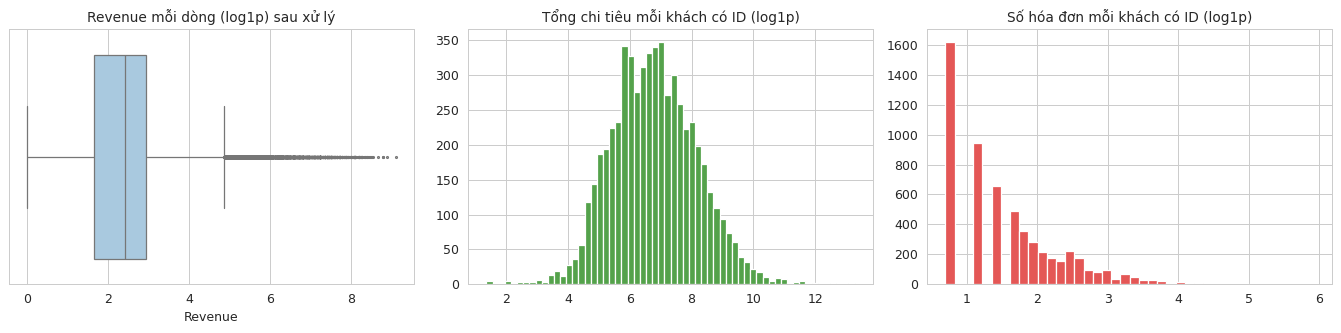

Skew cấp khách hàng (thang gốc): {'n_invoice': 12.05, 'spend': 26.3} | sau log1p: {'n_invoice': 1.0, 'spend': 0.24}


In [ ]:
reg_c = clean[~clean["IsGuest"]]
cust = reg_c.groupby("Customer ID").agg(n_invoice=("Invoice", "nunique"), spend=("Revenue", "sum"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=np.log1p(clean["Revenue"]), ax=axes[0], fliersize=1.5, color="#A0CBE8"); axes[0].set_title("Revenue mỗi dòng (log1p) sau xử lý")
axes[1].hist(np.log1p(cust["spend"]), bins=60, color="#54A24B"); axes[1].set_title("Tổng chi tiêu mỗi khách có ID (log1p)")
axes[2].hist(np.log1p(cust["n_invoice"]), bins=40, color="#E45756"); axes[2].set_title("Số hóa đơn mỗi khách có ID (log1p)")
plt.tight_layout(); plt.show()
print("Skew cấp khách hàng (thang gốc):", cust.skew().round(2).to_dict(), "| sau log1p:", np.log1p(cust).skew().round(2).to_dict())

In [ ]:
pp.save_processed(clean, log_df, ROOT / "data" / "processed")
for f in sorted((ROOT / "data" / "processed").glob("*")):
    if f.name in ("data_clean.csv.gz", "cleaning_log.csv"):
        print(f"{f.name:22s} {f.stat().st_size/1e6:8.2f} MB")

chk = pd.read_csv(ROOT / "data" / "processed" / "data_clean.csv.gz", parse_dates=["InvoiceDate"], dtype={"Customer ID": str})
print("Đọc lại:", chk.shape, "| khớp số dòng:", len(chk) == len(clean), "| Revenue khớp:", np.isclose(chk["Revenue"].sum(), clean["Revenue"].sum()))

cleaning_log.csv           0.00 MB
data_clean.csv.gz         16.44 MB


Đọc lại: (1002995, 10) | khớp số dòng: True | Revenue khớp: True
